In [1]:
#use env spatial
from STalign import STalign


In [2]:
#run using env_stalign from here
import pandas as pd
import scanpy as sc
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import anndata as ad

refExpression = pd.read_csv('refSubAD_expression.csv', index_col=0)
queryExpression = pd.read_csv('querySubAD_expression.csv', index_col=0)
refObs = pd.read_csv('refSubAD_obs.csv', index_col=0)
queryObs = pd.read_csv('querySubAD_obs.csv', index_col=0)


refAD = ad.AnnData(X=refExpression.values, obs=refObs)
queryAD = ad.AnnData(X=queryExpression.values, obs=queryObs)

refAD.var_names = refExpression.columns
queryAD.var_names = queryExpression.columns



/home/adyprat/anaconda3/envs/spatial/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)
/home/adyprat/anaconda3/envs/spatial/lib/python3.8/site-packages/anndata/_core/anndata.py:120: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


In [3]:
refAD.var_names == queryAD.var_names

array([ True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True])

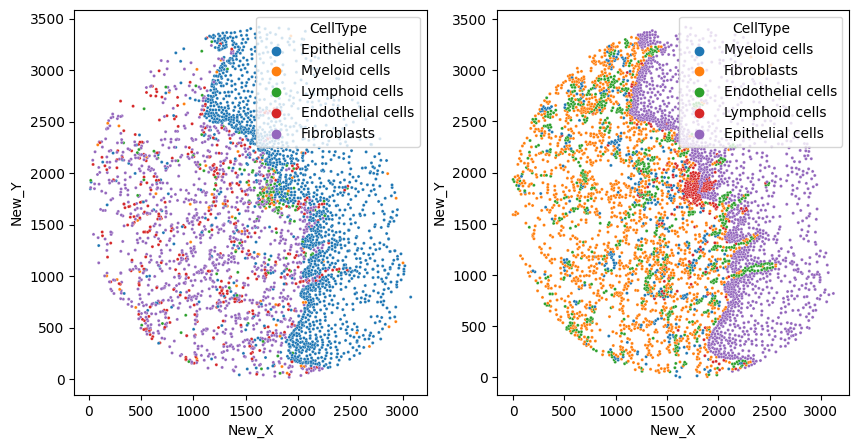

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2, figsize=(10, 5))
sns.scatterplot(data=refAD.obs, x='New_X', y='New_Y', hue='CellType', ax=ax[0],s=5)
sns.scatterplot(data=queryAD.obs, x='New_X', y='New_Y', hue='CellType', ax=ax[1],s=5)

plt.show()


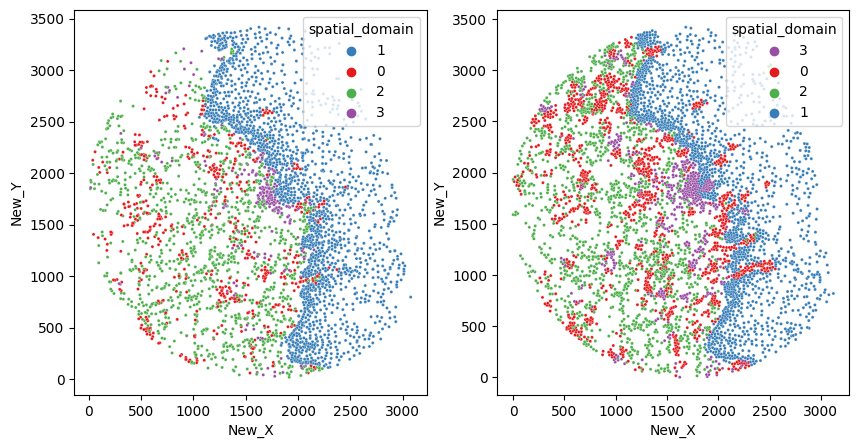

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1,2, figsize=(10, 5))
refAD.obs['spatial_domain'] = refAD.obs['spatial_domain'].astype(str)
queryAD.obs['spatial_domain'] = queryAD.obs['spatial_domain'].astype(str)
colors = sns.color_palette('Set1', 4)
palette_dict = {str(i):colors[i] for i in range(4)}
sns.scatterplot(data=refAD.obs, x='New_X', y='New_Y', hue='spatial_domain', ax=ax[0],s=5, palette=palette_dict)
sns.scatterplot(data=queryAD.obs, x='New_X', y='New_Y', hue='spatial_domain', ax=ax[1],s=5, palette=palette_dict)

plt.show()


In [6]:
import seaborn as sns

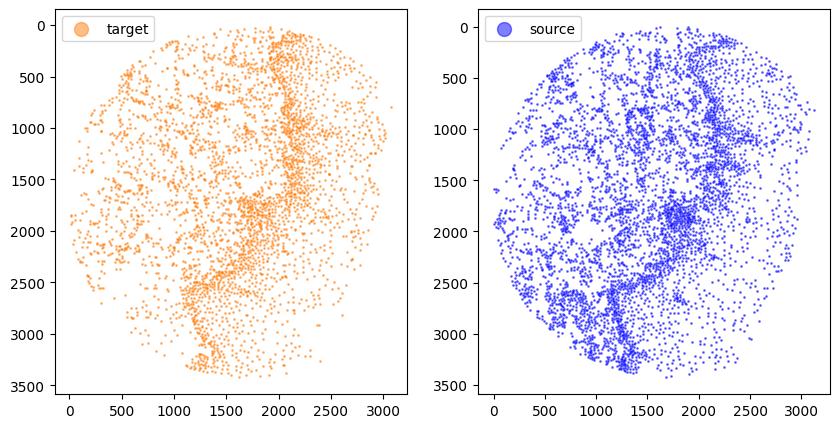

In [7]:
# xI = queryAD.obs['spot_x'].values/10
# yI = queryAD.obs['spot_y'].values/10
# xJ = refAD.obs['spot_x'].values/10
# yJ = refAD.obs['spot_y'].values/10

xI = queryAD.obs['New_X'].values
yI = queryAD.obs['New_Y'].values
xJ = refAD.obs['New_X'].values
yJ = refAD.obs['New_Y'].values
xJ = xJ.astype(int)
yJ = yJ.astype(int)
xI = xI.astype(int)
yI = yI.astype(int)
import matplotlib.pyplot as plt
fig,ax = plt.subplots(1,2, figsize=(10, 5))

ax[0].scatter(xJ,yJ,s=1,alpha=0.5,c='#ff7f0e', label='target')
ax[1].scatter(xI,yI,s=1,alpha=0.5,c='blue', label='source')
ax[0].legend(markerscale = 10)
ax[1].legend(markerscale = 10)
ax[0].invert_yaxis()
ax[1].invert_yaxis()





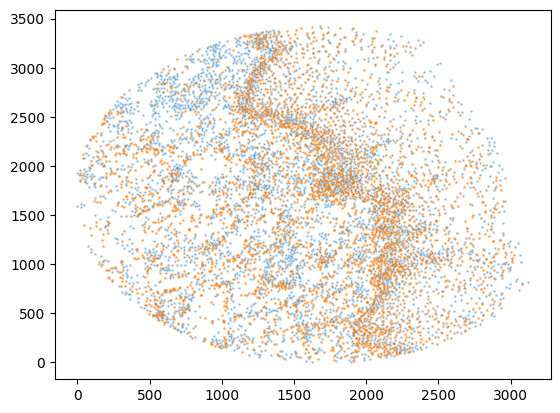

In [8]:
# plot
fig,ax = plt.subplots()
ax.scatter(xI,yI,s=1,alpha=0.3)
ax.scatter(xJ,yJ,s=1,alpha=0.5)

In [9]:
sJ = refAD.X
sI = queryAD.X



In [10]:
sI.shape, sJ.shape

((4671, 16), (3608, 16))

0 of 3608
100 of 3608
200 of 3608
300 of 3608
400 of 3608
500 of 3608
600 of 3608
700 of 3608
800 of 3608
900 of 3608
1000 of 3608
1100 of 3608
1200 of 3608
1300 of 3608
1400 of 3608
1500 of 3608
1600 of 3608
1700 of 3608
1800 of 3608
1900 of 3608
2000 of 3608
2100 of 3608
2200 of 3608
2300 of 3608
2400 of 3608
2500 of 3608
2600 of 3608
2700 of 3608
2800 of 3608
2900 of 3608
3000 of 3608
3100 of 3608
3200 of 3608
3300 of 3608
3400 of 3608
3500 of 3608
3600 of 3608
3607 of 3608
0 of 4671
100 of 4671
200 of 4671
300 of 4671
400 of 4671
500 of 4671
600 of 4671
700 of 4671
800 of 4671
900 of 4671
1000 of 4671
1100 of 4671
1200 of 4671
1300 of 4671
1400 of 4671
1500 of 4671
1600 of 4671
1700 of 4671
1800 of 4671
1900 of 4671
2000 of 4671
2100 of 4671
2200 of 4671
2300 of 4671
2400 of 4671
2500 of 4671
2600 of 4671
2700 of 4671
2800 of 4671
2900 of 4671
3000 of 4671
3100 of 4671
3200 of 4671
3300 of 4671
3400 of 4671
3500 of 4671
3600 of 4671
3700 of 4671
3800 of 4671
3900 of 4671
4000 of 46

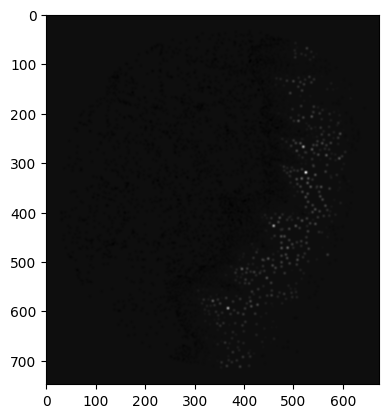

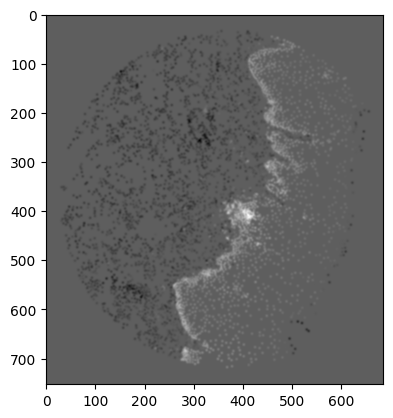

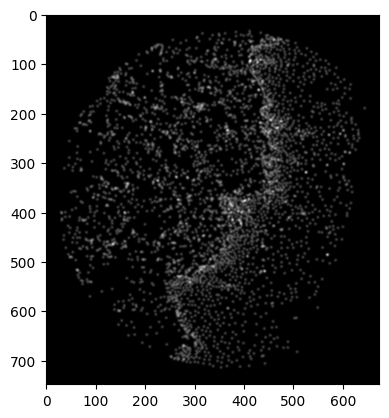

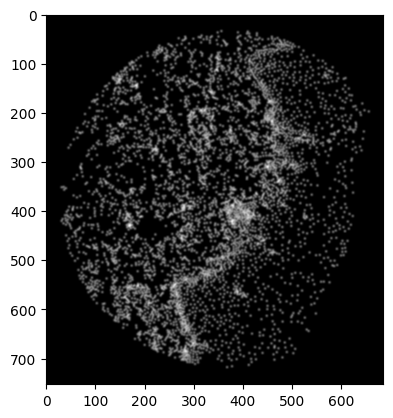

In [11]:
from STalign import STalign
sc.tl.pca(refAD, n_comps=4)
sc.tl.pca(queryAD, n_comps=4)

XJ,YJ,J,fig = STalign.rasterize_with_signal(xJ,yJ,refAD.obsm['X_pca'],dx=5, draw=100)
XI,YI,I,fig = STalign.rasterize_with_signal(xI,yI,queryAD.obsm['X_pca'],dx=5, draw=100)


XJ,YJ,J,fig = STalign.rasterize(xJ,yJ,dx=5, draw=100)
XI,YI,I,fig = STalign.rasterize(xI,yI,dx=5, draw=100)



In [12]:
XJ.shape, J.shape, I.max()

((674,), (1, 748, 674), 0.10510663382798763)

In [13]:
# Min-max normalize I and J to 0-1
I = (I - I.min()) / (I.max() - I.min())
J = (J - J.min()) / (J.max() - J.min())


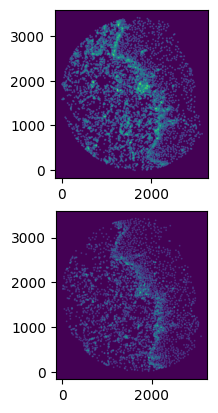

In [14]:
# get extent of images
extentI = STalign.extent_from_x((YI,XI))
extentJ = STalign.extent_from_x((YJ,XJ))

# plot rasterized images
ix = 0
fig,ax = plt.subplots(2,1)
I_sub = I[ix,:,:].squeeze()
J_sub = J[ix,:,:].squeeze()
ax[0].imshow(I_sub, extent=extentI)
ax[1].imshow(J_sub, extent=extentJ)
ax[0].invert_yaxis()
ax[1].invert_yaxis()

In [15]:
import torch # set device for building tensors
if torch.cuda.is_available():
    torch.set_default_device('cuda:0')
else:
    torch.set_default_device('cpu')

torch.cuda.is_available()

True

In [16]:
#from STalignLDDMM import LDDMM
from STalign.STalign import LDDMM

/home/adyprat/anaconda3/envs/spatial/lib/python3.8/site-packages/torch/utils/_device.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return func(*args, **kwargs)
/home/adyprat/anaconda3/envs/spatial/lib/python3.8/site-packages/torch/functional.py:504: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3483.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/home/adyprat/anaconda3/envs/spatial/lib/python3.8/site-packages/STalign/STalign.py:1301: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  axE[2].set_yscale('log')


CPU times: user 1min 50s, sys: 2.59 s, total: 1min 52s
Wall time: 1min 6s


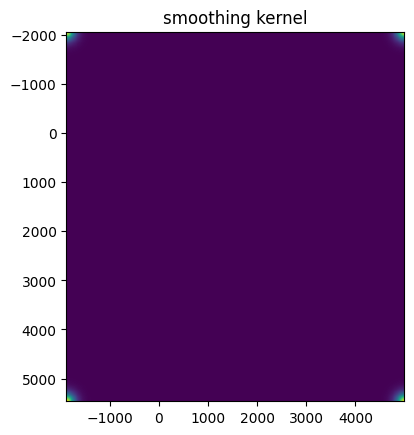

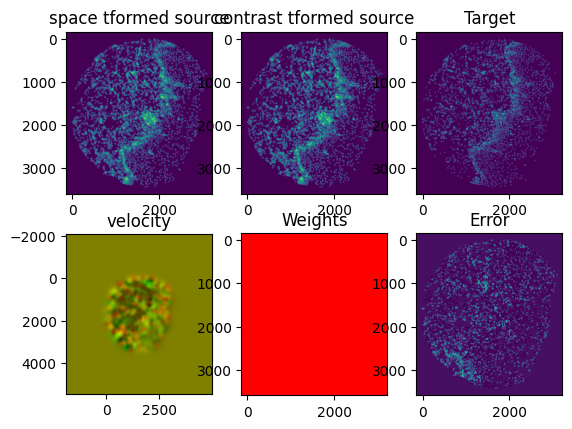

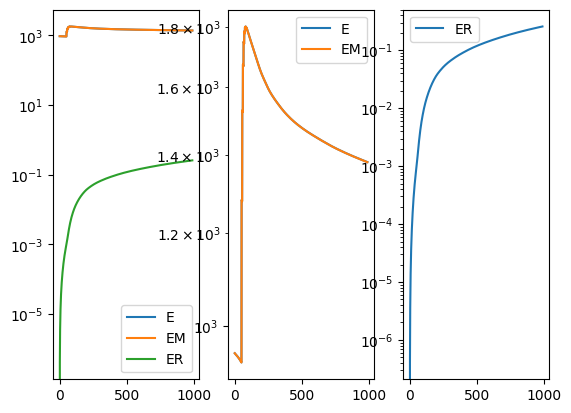

In [17]:
%%time
import numpy as np

# run LDDMM
# specify device (default device for STalign.LDDMM is cpu)
if torch.cuda.is_available():
    device = 'cuda:0'
else:
    device = 'cpu'

# keep all other parameters default
params = {
          'niter':1000,
          'device':device,
          'diffeo_start':0,
          'a':50,
          'epV':1000,
          #'muB': torch.tensor([0,0,0]), # black is background in target
          }
ix = 0
Ifoo = np.vstack((I[ix,:,:][None, ...], I[ix,:,:][None, ...], I[ix,:,:][None, ...])) # make RGB instead of greyscale
Jfoo = np.vstack((J[ix,:,:][None, ...], J[ix,:,:][None, ...], J[ix,:,:][None, ...])) # make RGB instead of greyscale

Ifoo = I # make RGB instead of greyscale
Jfoo = J # make RGB instead of greyscale
out = LDDMM([YI,XI],Ifoo,[YJ,XJ],Jfoo,**params)

In [18]:
# get necessary output variables
A = out['A']
v = out['v']
xv = out['xv']

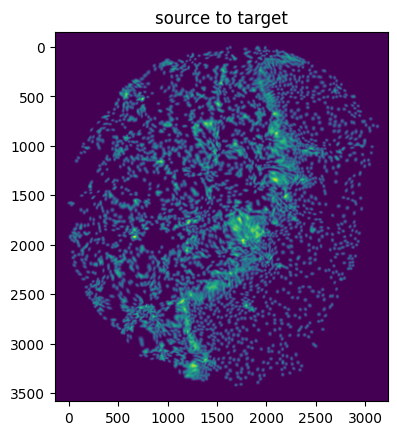

In [19]:
# apply transform
phii = STalign.build_transform(xv,v,A,XJ=[YJ,XJ],direction='b')
phiI = STalign.transform_image_source_to_target(xv,v,A,[YI,XI],Ifoo,[YJ,XJ])

#switch tensor from cuda to cpu for plotting with numpy
if phii.is_cuda:
    phii = phii.cpu()
if phiI.is_cuda:
    phiI = phiI.cpu()

# plot with grids
fig,ax = plt.subplots()
levels = np.arange(-10000,10000,100)
# ax.contour(XJ,YJ,phii[...,0],colors='r',linestyles='-',levels=levels)
# ax.contour(XJ,YJ,phii[...,1],colors='g',linestyles='-',levels=levels)
ax.set_aspect('equal')
ax.set_title('source to target')
ax.imshow(phiI[:,:].permute(1,2,0)/torch.max(phiI),extent=extentJ)

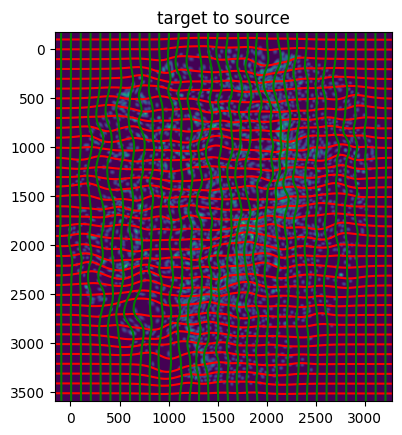

In [20]:
# apply transform
phij = STalign.build_transform(xv,v,A,XJ=[YI,XI],direction='f')
phijJ = STalign.transform_image_target_to_source(xv,v,A,[YI,XI],Jfoo,[YI,XI])

#switch tensor from cuda to cpu for plotting with numpy
if phij.is_cuda:
    phij = phij.cpu()
if phijJ.is_cuda:
    phijJ = phijJ.cpu()

# plot with grids
fig,ax = plt.subplots()
levels = np.arange(-10000,10000,100)
ax.contour(XI,YI,phij[...,0],colors='r',linestyles='-',levels=levels)
ax.contour(XI,YI,phij[...,1],colors='g',linestyles='-',levels=levels)
ax.set_aspect('equal')
ax.set_title('target to source')
ax.imshow(phijJ[:,:].permute(1,2,0)/torch.max(phijJ),extent=extentI)

In [21]:
xv_int = [t.to(torch.int) for t in xv]
xv_int

[tensor([-2051, -2026, -2001, -1976, -1951, -1926, -1901, -1876, -1851, -1826,
         -1801, -1776, -1751, -1726, -1701, -1676, -1651, -1626, -1601, -1576,
         -1551, -1526, -1501, -1476, -1451, -1426, -1401, -1376, -1351, -1326,
         -1301, -1276, -1251, -1226, -1201, -1176, -1151, -1126, -1101, -1076,
         -1051, -1026, -1001,  -976,  -951,  -926,  -901,  -876,  -851,  -826,
          -801,  -776,  -751,  -726,  -701,  -676,  -651,  -626,  -601,  -576,
          -551,  -526,  -501,  -476,  -451,  -426,  -401,  -376,  -351,  -326,
          -301,  -276,  -251,  -226,  -201,  -176,  -151,  -126,  -101,   -76,
           -51,   -26,    -1,    24,    49,    74,    99,   124,   149,   174,
           199,   224,   249,   274,   299,   324,   349,   374,   399,   424,
           449,   474,   499,   524,   549,   574,   599,   624,   649,   674,
           699,   724,   749,   774,   799,   824,   849,   874,   899,   924,
           949,   974,   999,  1024,  1049,  1074,  

In [22]:
# Ensure input types match grid types (FloatTensor, not DoubleTensor)
points_np = np.stack([yJ, xJ], 1).astype(np.float32)
points_tensor = torch.from_numpy(points_np).to(xv[0].device).type(xv[0].dtype)
tpointsJ  = STalign.transform_points_target_to_source(xv_int,v,A, points_tensor)


#switch from row column coordinates (y,x) to (x,y)
xJ_LDDMM = tpointsJ[:,1]
yJ_LDDMM = tpointsJ[:,0]


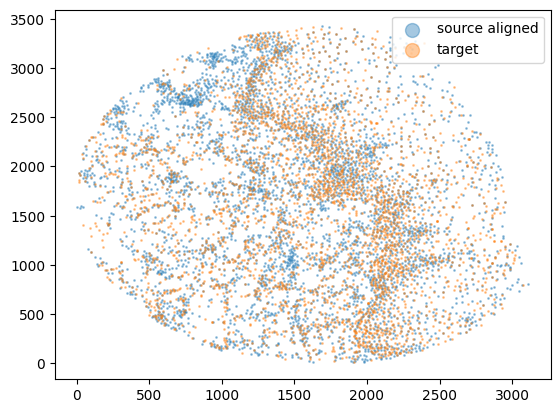

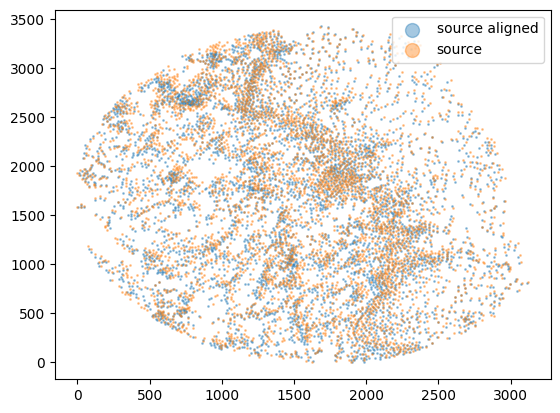

In [23]:


# Ensure input types match grid types (FloatTensor, not DoubleTensor)
points_np = np.stack([yI, xI], 1).astype(np.float32)
points_tensor = torch.from_numpy(points_np).to(xv[0].device).type(xv[0].dtype)
tpointsI = STalign.transform_points_source_to_target(
    xv, v, A, points_tensor, 
)

#switch tensor from cuda to cpu for plotting with numpy
if tpointsI.is_cuda:
    tpointsI = tpointsI.cpu()

#switch from row column coordinates (y,x) to (x,y)
xI_LDDMM = tpointsI[:,1]
yI_LDDMM = tpointsI[:,0]

# plot results
fig,ax = plt.subplots()
#ax.scatter(xJ,yJ,s=1,alpha=0.3, label='source')
ax.scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.4, label = 'source aligned')
ax.scatter(xJ,yJ,s=1,alpha=0.4, label='target')
ax.legend(markerscale = 10)

fig,ax = plt.subplots()
ax.scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.4, label='source aligned')
ax.scatter(xI,yI,s=1,alpha=0.4, label='source')
ax.legend(markerscale = 10)

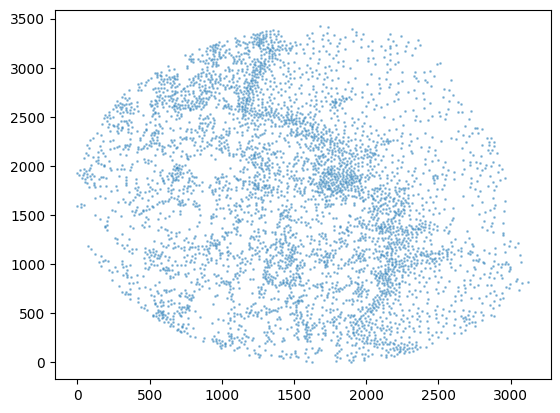

In [24]:
plt.scatter(xI,yI,s=1,alpha=0.4, label = 'source aligned')


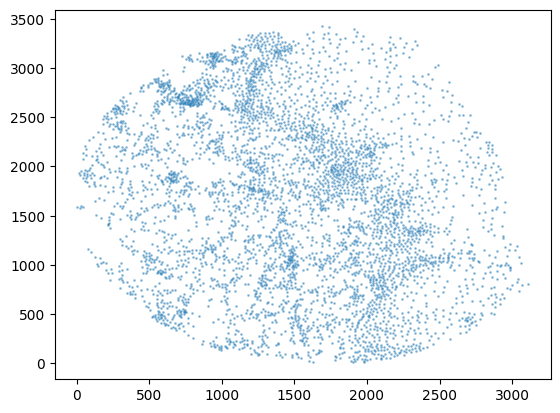

In [25]:
plt.scatter(xI_LDDMM,yI_LDDMM,s=1,alpha=0.4, label = 'source aligned')


In [26]:
xJ.shape

(3608,)

In [27]:
xJ_LDDMM.shape

torch.Size([3608])

In [28]:
queryAD

AnnData object with n_obs × n_vars = 4671 × 16
    obs: 'Image', 'Object ID', 'Object type', 'Name', 'Classification', 'Parent', 'ROI', 'Centroid X µm', 'Centroid Y µm', 'Nucleus: Area', 'Nucleus: Perimeter', 'Nucleus: Circularity', 'Nucleus: Max caliper', 'Nucleus: Min caliper', 'Nucleus: Eccentricity', 'Nucleus: DAPI sum', 'Nucleus: DAPI std dev', 'Nucleus: DAPI max', 'Nucleus: DAPI min', 'Nucleus: DAPI range', 'Nucleus: CD8 sum', 'Nucleus: CD8 std dev', 'Nucleus: CD8 max', 'Nucleus: CD8 min', 'Nucleus: CD8 range', 'Nucleus: CD20 sum', 'Nucleus: CD20 std dev', 'Nucleus: CD20 max', 'Nucleus: CD20 min', 'Nucleus: CD20 range', 'Nucleus: CD4 sum', 'Nucleus: CD4 std dev', 'Nucleus: CD4 max', 'Nucleus: CD4 min', 'Nucleus: CD4 range', 'Nucleus: GZMB sum', 'Nucleus: GZMB std dev', 'Nucleus: GZMB max', 'Nucleus: GZMB min', 'Nucleus: GZMB range', 'Nucleus: FOXP3 sum', 'Nucleus: FOXP3 std dev', 'Nucleus: FOXP3 max', 'Nucleus: FOXP3 min', 'Nucleus: FOXP3 range', 'Nucleus: Ki67 sum', 'Nucleus: Ki

In [29]:
queryAD.obs.loc[:, 'STAlign_X'] = xI_LDDMM
queryAD.obs.loc[:, 'STAlign_Y'] = yI_LDDMM



In [30]:
refAD

AnnData object with n_obs × n_vars = 3608 × 16
    obs: 'fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x', 'max_y', 'anisotropy', 'transcript_count', 'perimeter_area_ratio', 'solidity', 'Anti-Chicken_raw', 'Anti-Chicken_high_pass', 'PolyT_raw', 'PolyT_high_pass', 'Cellbound2_raw', 'Cellbound2_high_pass', 'Anti-Human_raw', 'Anti-Human_high_pass', 'DAPI_raw', 'DAPI_high_pass', 'Anti-Rat_raw', 'Anti-Rat_high_pass', 'Anti-Mouse_raw', 'Anti-Mouse_high_pass', 'Cellbound3_raw', 'Cellbound3_high_pass', 'Cellbound1_raw', 'Cellbound1_high_pass', 'Anti-Goat_raw', 'Anti-Goat_high_pass', 'Anti-Rabbit_raw', 'Anti-Rabbit_high_pass', 'DAPI_raw_log', 'n_counts', 'transformed_x', 'transformed_y', 'in_ROI', 'pred_cell_type', 'New_X', 'New_Y', 'CellType', 'image_id', 'spatial_domain'
    uns: 'pca'
    obsm: 'X_pca'
    varm: 'PCs'

In [31]:
import numpy as np

# Assuming refAD is your reference AnnData object with 'spot_x', 'spot_y', and 'CellType' in .obs
# and queryAD is your query AnnData object with 'STAlign_X', 'STAlign_Y', and 'CellType' in .obs

# Get coordinates from refAD and queryAD
ref_coords = refAD.obs[['New_X', 'New_Y']].values
query_coords = queryAD.obs[['STAlign_X', 'STAlign_Y']].values

# Get cell types
ref_celltypes = refAD.obs['CellType'].values
query_celltypes = queryAD.obs['CellType'].values

# For each query cell, find the nearest ref cell and compare CellType
from scipy.spatial import cKDTree

tree = cKDTree(ref_coords)
dists, idxs = tree.query(query_coords, k=1)

# Compare cell types
matches = query_celltypes == ref_celltypes[idxs]

# Optionally, print or summarize the results
print(f"Number of matches: {np.sum(matches)} / {len(matches)}")
print(f"Match percentage: {np.mean(matches)*100:.2f}%")

# If you want to see which ones matched/mismatched:
queryAD.obs['NearestRefCellType'] = ref_celltypes[idxs]
queryAD.obs['CellTypeMatch'] = matches


Number of matches: 2939 / 4671
Match percentage: 62.92%


In [ ]:
import numpy as np
from scipy.optimize import linear_sum_assignment

# Get coordinates from refAD and queryAD
ref_coords = refAD.obs[['New_X', 'New_Y']].values
query_coords = queryAD.obs[['STAlign_X', 'STAlign_Y']].values


tau = 250.0          # <-- set your cutoff (same units as coords)
LARGE = 1e9         # sentinel cost

# Compute the cost matrix (Euclidean distance between each query and each ref)
cost_matrix = np.linalg.norm(query_coords[:, None, :] - ref_coords[None, :, :], axis=2)
masked = cost_matrix.copy()

masked[masked > tau] = LARGE

# Hungarian algorithm for 1-1 matching (minimize total distance)
row_ind, col_ind = linear_sum_assignment(cost_matrix)
# Get cell types
ref_celltypes = refAD.obs['CellType'].values
query_celltypes = queryAD.obs['CellType'].values
# Compare cell types for matched pairs
matched_query_celltypes = query_celltypes[row_ind]
matched_ref_celltypes = ref_celltypes[col_ind]
matches = matched_query_celltypes == matched_ref_celltypes

# Optionally, print or summarize the results
print(f"Number of matches: {np.sum(matches)} / {len(matches)}")
print(f"Match percentage: {np.mean(matches)*100:.2f}%")

# Store results in queryAD.obs for matched queries
queryAD.obs['Hungarian_NearestRefCellType'] = pd.Series(index=queryAD.obs.index, dtype=object)
queryAD.obs['Hungarian_CellTypeMatch'] = pd.Series(index=queryAD.obs.index, dtype=object)
queryAD.obs.loc[queryAD.obs.index[row_ind], 'Hungarian_NearestRefCellType'] = matched_ref_celltypes
queryAD.obs.loc[queryAD.obs.index[row_ind], 'Hungarian_CellTypeMatch'] = matches



# Get cell types
ref_celltypes = refAD.obs['spatial_domain'].values
query_celltypes = queryAD.obs['spatial_domain'].values
# Compare cell types for matched pairs
matched_query_celltypes = query_celltypes[row_ind]
matched_ref_celltypes = ref_celltypes[col_ind]
matches = matched_query_celltypes == matched_ref_celltypes

# Optionally, print or summarize the results
print(f"Number of matches: {np.sum(matches)} / {len(matches)}")
print(f"Match percentage: {np.mean(matches)*100:.2f}%")





Number of matches: 2387 / 3608
Match percentage: 66.16%
Number of matches: 2478 / 3608
Match percentage: 68.68%


In [75]:
refAD.obs.columns

Index(['fov', 'volume', 'center_x', 'center_y', 'min_x', 'min_y', 'max_x',
       'max_y', 'anisotropy', 'transcript_count', 'perimeter_area_ratio',
       'solidity', 'Anti-Chicken_raw', 'Anti-Chicken_high_pass', 'PolyT_raw',
       'PolyT_high_pass', 'Cellbound2_raw', 'Cellbound2_high_pass',
       'Anti-Human_raw', 'Anti-Human_high_pass', 'DAPI_raw', 'DAPI_high_pass',
       'Anti-Rat_raw', 'Anti-Rat_high_pass', 'Anti-Mouse_raw',
       'Anti-Mouse_high_pass', 'Cellbound3_raw', 'Cellbound3_high_pass',
       'Cellbound1_raw', 'Cellbound1_high_pass', 'Anti-Goat_raw',
       'Anti-Goat_high_pass', 'Anti-Rabbit_raw', 'Anti-Rabbit_high_pass',
       'DAPI_raw_log', 'n_counts', 'transformed_x', 'transformed_y', 'in_ROI',
       'pred_cell_type', 'New_X', 'New_Y', 'CellType', 'image_id',
       'spatial_domain'],
      dtype='object')

In [74]:
queryAD.obs.drop(columns=['Hungarian_NearestRefCellType','Hungarian_CellTypeMatch', 'NearestRefCellType','CellTypeMatch','Hungarian_CNMatch', 'Hungarian_NearestRefCN'], inplace=True)

In [ ]:
queryAD.obsm['X_STAlign_spatial'] = queryAD.obs[['STAlign_X', 'STAlign_Y']].values
queryAD.write_h5ad('query_STAlign_Prot_tongue.h5ad')

refAD.obsm['X_STAlign_spatial'] = refAD.obs[['New_X', 'New_Y']].values
refAD.write_h5ad('ref_STAlign_RNA_tongue.h5ad')

/home/adyprat/anaconda3/envs/spatial/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'pred_cell_type' as categorical
/home/adyprat/anaconda3/envs/spatial/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will be removed in a future version. Reordering categories will always return a new Categorical object.
  c.reorder_categories(natsorted(c.categories), inplace=True)
... storing 'CellType' as categorical
/home/adyprat/anaconda3/envs/spatial/lib/python3.8/site-packages/anndata/_core/anndata.py:1228: FutureWarning: The `inplace` parameter in pandas.Categorical.reorder_categories is deprecated and will